<a href="https://colab.research.google.com/github/GuiCastro7/Grupo-3---ECAA08/blob/main/Aula%2024%20-%20%C3%81rvore%20de%20Atingibilidade%20e%20Cobertura%20em%20Redes%20de%20Petri%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árvore de Atingibilidade e Árvore de Cobertura (Karp-Miller) em Redes de Petri
### Linha Automatizada de Envase e Inspeção de Bebidas — Grupo 3 (ECAA08)

Este notebook implementa do zero os algoritmos formais de **Árvore de Atingibilidade (*Reachability Tree*)** e **Árvore de Cobertura (*Coverability Tree* — Algoritmo de Karp-Miller)** aplicados ao controle discreto do subsistema de dosagem (`TS1`/`BC1`/`AS1`/`VS2`) e acúmulo de garrafas sobre a esteira `RC1` na **Linha de Envase e Inspeção de Bebidas (`SCADA-Core`)**.

---
## Roteiro de Execução
1. **Modelagem Matricial da Rede de Petri** ($N = (P, T, \text{Pre}, \text{Post}, M_0)$) via matriz de incidência $C = \text{Post} - \text{Pre}$.
2. **Cenário A (Rede Não-Limitada):** Árvore de Cobertura com símbolo $\omega$ detectando risco de acúmulo infinito de garrafas na esteira `RC1`.
3. **Cenário B (Correção Estrutural por Lugar Complementar — Invariante-P):** Limitação física de $K_{\max} = 2$ vagas no pulmão de `RC1` e escoamento via tampagem/inspeção (`AC1`/`SL1`/`SFC1`).
4. **Auditoria Automática** de *Limitação*, *Segurança*, *Deadlocks*, *Reversibilidade* e *Vivacidade (L4-Live)* + visualização gráfica do Grafo de Atingibilidade.

### 1. Definição Formal da Rede de Petri (Cenário A — Sem Limite em `RC1`)

| Lugar | Descrição Física / Tag ISA-5.1 | Marcação Inicial $M_0$ |
| :--- | :--- | :---: |
| `P1_BEBIDA_TS1` | Dose de bebida disponível no Reservatório `TS1` (`SP1` ok) | `1` |
| `P2_GARRAFA_VAZIA` | Garrafa vazia posicionada sob o bico `VS2` na esteira `RC1` | `1` |
| `P3_ENVASE_LIVRE` | Estação de Dosagem (`AS1`/`VS2`) pressurizada e livre (`SP2` ok) | `1` |
| `P4_ENVASANDO` | Dosagem volumétrica em curso (`VS2` aberta, `SQ2` ativo) | `0` |
| `P5_RC1_ACUMULO` | Garrafas envasadas acumuladas no pulmão de `RC1` antes de `AC1`/`SFC1` | `0` |

**Transições ($T$):**
* `T1_INICIAR_ENVASE`: Abertura de `VS2` (consome 1 dose de bebida, 1 garrafa vazia e ocupa a estação).
* `T2_CONCLUIR_ENVASE`: Fechamento de `VS2` (libera a estação e deposita 1 garrafa cheia na esteira `RC1`).
* `T3_REABASTECER_LINHA`: Reposição contínua de bebida em `TS1` e entrada de nova garrafa vazia.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

class RedeDePetri:
    def __init__(self, lugares, transicoes, pre, post, m0):
        self.lugares = lugares
        self.transicoes = transicoes
        self.Pre = np.array(pre, dtype=int)   # Matriz |P| x |T| (arcos de entrada)
        self.Post = np.array(post, dtype=int) # Matriz |P| x |T| (arcos de saída)
        self.C = self.Post - self.Pre         # Matriz de Incidência C = Post - Pre
        self.M0 = tuple(m0)

    def exibir_matrizes(self):
        df_c = pd.DataFrame(self.C, index=self.lugares, columns=self.transicoes)
        print("=== MATRIZ DE INCIDÊNCIA (C = Post - Pre) ===")
        display(df_c)

# ==============================================================================
# CENÁRIO A: REDE SEM LIMITE FÍSICO EXPLÍCITO NO PULMÃO DA ESTEIRA RC1
# ==============================================================================
lugares_A = [
    "P1_BEBIDA_TS1",
    "P2_GARRAFA_VAZIA",
    "P3_ENVASE_LIVRE",
    "P4_ENVASANDO",
    "P5_RC1_ACUMULO"
]

transicoes_A = [
    "T1_INICIAR_ENVASE",
    "T2_CONCLUIR_ENVASE",
    "T3_REABASTECER_LINHA"
]

Pre_A = [
    [1, 0, 0],  # P1_BEBIDA_TS1
    [1, 0, 0],  # P2_GARRAFA_VAZIA
    [1, 0, 0],  # P3_ENVASE_LIVRE
    [0, 1, 0],  # P4_ENVASANDO
    [0, 0, 0],  # P5_RC1_ACUMULO
]

Post_A = [
    [0, 0, 1],  # P1_BEBIDA_TS1 (T3 reabastece)
    [0, 0, 1],  # P2_GARRAFA_VAZIA (T3 alimenta nova garrafa)
    [0, 1, 0],  # P3_ENVASE_LIVRE (T2 libera estação de envase)
    [1, 0, 0],  # P4_ENVASANDO (T1 inicia dosagem em VS2)
    [0, 1, 0],  # P5_RC1_ACUMULO (T2 acumula garrafa cheia na esteira RC1)
]

M0_A = (1, 1, 1, 0, 0)

rdp_ilimitada = RedeDePetri(lugares_A, transicoes_A, Pre_A, Post_A, M0_A)
rdp_ilimitada.exibir_matrizes()

=== MATRIZ DE INCIDÊNCIA (C = Post - Pre) ===


,T1_INICIAR_ENVASE,T2_CONCLUIR_ENVASE,T3_REABASTECER_LINHA
P1_BEBIDA_TS1,-1,0,1
P2_GARRAFA_VAZIA,-1,0,1
P3_ENVASE_LIVRE,-1,1,0
P4_ENVASANDO,1,-1,0
P5_RC1_ACUMULO,0,1,0


### 2. Algoritmo de Karp-Miller (Árvore de Cobertura)
Quando um lugar pode acumular fichas sem limite, substituímos essa coordenada por **$\omega$** sempre que o novo estado $M'$ domina um ancestral $M$ no mesmo ramo ($M' \ge M$ e $M' \neq M$), garantindo que a árvore termine em um número finito de passos.

In [2]:
OMEGA = float("inf")

def formatar_marcacao(M):
    return "(" + ", ".join("ω" if x == OMEGA else str(int(x)) for x in M) + ")"

def esta_habilitada(M, pre_col):
    return all(m_val >= req for m_val, req in zip(M, pre_col))

def disparar_transicao(M, pre_col, post_col):
    M_novo = []
    for m_val, req, prod in zip(M, pre_col, post_col):
        if m_val == OMEGA:
            M_novo.append(OMEGA)
        else:
            M_novo.append(int(m_val - req + prod))
    return tuple(M_novo)

def aplicar_aceleracao_omega(M_novo, caminho_ancestrais):
    M_acelerado = list(M_novo)
    for M_anc in caminho_ancestrais:
        if all(m_n >= m_a for m_n, m_a in zip(M_acelerado, M_anc)) and tuple(M_acelerado) != M_anc:
            for i in range(len(M_acelerado)):
                if M_acelerado[i] > M_anc[i]:
                    M_acelerado[i] = OMEGA
    return tuple(M_acelerado)

def construir_arvore_cobertura(rdp, max_nos=200):
    arvore = nx.DiGraph()
    grafo_cobertura = nx.DiGraph()

    raiz_id = "S0"
    arvore.add_node(raiz_id, marcacao=rdp.M0, label=formatar_marcacao(rdp.M0), tipo="Raiz")
    grafo_cobertura.add_node(rdp.M0, label=formatar_marcacao(rdp.M0))

    marcacoes_exploradas = set()
    fila = deque([(raiz_id, rdp.M0, [rdp.M0])])
    contador_nos = 1

    while fila and contador_nos < max_nos:
        no_id, M_atual, ancestrais = fila.popleft()

        if M_atual in marcacoes_exploradas:
            arvore.nodes[no_id]["tipo"] = "Duplicado (Old)"
            continue

        marcacoes_exploradas.add(M_atual)
        habilitadas = []

        for j, t_nome in enumerate(rdp.transicoes):
            pre_col = rdp.Pre[:, j]
            post_col = rdp.Post[:, j]

            if esta_habilitada(M_atual, pre_col):
                habilitadas.append(t_nome)
                M_bruto = disparar_transicao(M_atual, pre_col, post_col)
                M_prox = aplicar_aceleracao_omega(M_bruto, ancestrais)

                filho_id = f"S{contador_nos}"
                contador_nos += 1

                tipo_no = "Duplicado (Old)" if M_prox in marcacoes_exploradas else "Ativo"
                arvore.add_node(filho_id, marcacao=M_prox, label=formatar_marcacao(M_prox), tipo=tipo_no)
                arvore.add_edge(no_id, filho_id, transicao=t_nome)

                grafo_cobertura.add_node(M_prox, label=formatar_marcacao(M_prox))
                grafo_cobertura.add_edge(M_atual, M_prox, transicao=t_nome)

                if M_prox not in marcacoes_exploradas:
                    fila.append((filho_id, M_prox, ancestrais + [M_prox]))

        if not habilitadas and arvore.nodes[no_id]["tipo"] != "Raiz":
            arvore.nodes[no_id]["tipo"] = "DEADLOCK (Terminal)"

    return arvore, grafo_cobertura

arvore_A, grafo_A = construir_arvore_cobertura(rdp_ilimitada)
print(f"Árvore de Cobertura (Cenário A) gerada com {arvore_A.number_of_nodes()} nós e {grafo_A.number_of_nodes()} estados distintos.")
for n, d in arvore_A.nodes(data=True):
    print(f"  {n:4s}: M = {d['label']:22s} | Status: {d['tipo']}")

Árvore de Cobertura (Cenário A) gerada com 14 nós e 7 estados distintos.
  S0  : M = (1, 1, 1, 0, 0)        | Status: Raiz
  S1  : M = (0, 0, 0, 1, 0)        | Status: Ativo
  S2  : M = (ω, ω, 1, 0, 0)        | Status: Ativo
  S3  : M = (0, 0, 1, 0, 1)        | Status: Ativo
  S4  : M = (ω, ω, 0, 1, 0)        | Status: Ativo
  S5  : M = (ω, ω, 0, 1, 0)        | Status: Duplicado (Old)
  S6  : M = (ω, ω, 1, 0, 0)        | Status: Duplicado (Old)
  S7  : M = (ω, ω, 1, 0, ω)        | Status: Ativo
  S8  : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S9  : M = (ω, ω, 0, 1, 0)        | Status: Duplicado (Old)
  S10 : M = (ω, ω, 0, 1, ω)        | Status: Ativo
  S11 : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S12 : M = (ω, ω, 1, 0, ω)        | Status: Duplicado (Old)
  S13 : M = (ω, ω, 0, 1, ω)        | Status: Duplicado (Old)


### 3. Diagnóstico do Cenário A
O símbolo **$\omega$** na 5ª posição (`P5_RC1_ACUMULO`) comprova formalmente que, sem intertravamento de capacidade na esteira `RC1`, o envase pode acumular garrafas indefinidamente até causar engarrafamento e queda de produto.

### 4. Cenário B: Correção Estrutural via Lugar Complementar (Árvore de Atingibilidade Finita)
Adicionamos:
* `P6_RC1_VAGA` ($K_{\max} = 2$): garante o invariante $M(\text{P5\_RC1\_ACUMULO}) + M(\text{P6\_RC1\_VAGA}) = 2$.
* `P7_ENTRADA_VAGA` ($K_{\max} = 1$): limita o buffer de entrada.
* `T4_TAMPAR_INSPECIONAR`: escoamento via tampadora `AC1` e sensores `SL1`/`SFC1`.

In [3]:
lugares_B = [
    "P1_BEBIDA_TS1",
    "P2_GARRAFA_VAZIA",
    "P3_ENVASE_LIVRE",
    "P4_ENVASANDO",
    "P5_RC1_ACUMULO",
    "P6_RC1_VAGA",           # Lugar complementar do pulmão de RC1 (K_max = 2)
    "P7_ENTRADA_VAGA"        # Lugar complementar do buffer de entrada (K_max = 1)
]

transicoes_B = [
    "T1_INICIAR_ENVASE",
    "T2_CONCLUIR_ENVASE",
    "T3_REABASTECER_LINHA",
    "T4_TAMPAR_INSPECIONAR"  # Escoamento via AC1 / SL1 / SFC1
]

Pre_B = [
    [1, 0, 0, 0],  # P1_BEBIDA_TS1
    [1, 0, 0, 0],  # P2_GARRAFA_VAZIA
    [1, 0, 0, 0],  # P3_ENVASE_LIVRE
    [0, 1, 0, 0],  # P4_ENVASANDO
    [0, 0, 0, 1],  # P5_RC1_ACUMULO (T4 consome 1 garrafa para tampagem/inspeção)
    [0, 1, 0, 0],  # P6_RC1_VAGA (T2 exige vaga livre na esteira RC1!)
    [0, 0, 1, 0],  # P7_ENTRADA_VAGA (T3 exige vaga livre no buffer de entrada!)
]

Post_B = [
    [0, 0, 1, 0],  # P1_BEBIDA_TS1
    [0, 0, 1, 0],  # P2_GARRAFA_VAZIA
    [0, 1, 0, 0],  # P3_ENVASE_LIVRE
    [1, 0, 0, 0],  # P4_ENVASANDO
    [0, 1, 0, 0],  # P5_RC1_ACUMULO
    [0, 0, 0, 1],  # P6_RC1_VAGA (T4 libera vaga no pulmão de RC1)
    [1, 0, 0, 0],  # P7_ENTRADA_VAGA (T1 libera vaga no buffer de entrada)
]

M0_B = (1, 1, 1, 0, 0, 2, 0)

rdp_limitada = RedeDePetri(lugares_B, transicoes_B, Pre_B, Post_B, M0_B)
arvore_B, grafo_B = construir_arvore_cobertura(rdp_limitada)

print(f"Árvore de Atingibilidade (Cenário B) gerada com {grafo_B.number_of_nodes()} estados alcançáveis finitos!")

Árvore de Atingibilidade (Cenário B) gerada com 12 estados alcançáveis finitos!


### 5. Auditoria Automática de Propriedades Comportamentais (SED)
Comparamos formalmente o **Cenário A** e o **Cenário B** quanto à limitação, segurança, *deadlocks*, reversibilidade e vivacidade global (*L4-Live*).

In [4]:
def auditar_propriedades_rdp(rdp, grafo_estados, nome_cenario=""):
    estados = list(grafo_estados.nodes)
    n_lugares = len(rdp.lugares)

    max_por_lugar = [max(m[i] for m in estados) for i in range(n_lugares)]
    eh_limitada = all(v != OMEGA for v in max_por_lugar)
    eh_segura = all(v <= 1 for v in max_por_lugar)
    deadlocks = [m for m in estados if grafo_estados.out_degree(m) == 0]
    reversivel = nx.is_strongly_connected(grafo_estados) if eh_limitada else False
    transicoes_ativas = set(nx.get_edge_attributes(grafo_estados, "transicao").values())
    todas_vivas = (transicoes_ativas == set(rdp.transicoes)) and reversivel

    print("=========================================================================")
    print(f"AUDITORIA FORMAL DE PROPRIEDADES — {nome_cenario}")
    print("=========================================================================")
    print(f"• Total de Estados Distintos Alcançados: {len(estados)}")
    print(f"• Rede Limitada (k-Bounded):             {'SIM (Finita)' if eh_limitada else 'NÃO (Contém ω — Risco de Acúmulo em RC1!)'}")
    print(f"• Rede Segura (1-Bounded):               {'SIM' if eh_segura else 'NÃO (k > 1 no pulmão da esteira RC1)'}")
    print(f"• Deadlocks Detectados:                  {len(deadlocks)} {deadlocks if deadlocks else '(Zero bloqueios)'}")
    print(f"• Sistema Reversível (Retorna a M0):     {'SIM' if reversivel else 'NÃO'}")
    print(f"• Vivacidade Global (L4-Live):           {'SIM' if todas_vivas else 'NÃO'}")
    print("\nCapacidade Máxima Observada por Lugar:")
    for lug, vmax in zip(rdp.lugares, max_por_lugar):
        val_str = "∞ (ω)" if vmax == OMEGA else str(vmax)
        print(f"  - {lug:20s}: max = {val_str}")
    print()

auditar_propriedades_rdp(rdp_ilimitada, grafo_A, "CENÁRIO A (Sem Controle de Capacidade na Esteira RC1)")
auditar_propriedades_rdp(rdp_limitada, grafo_B, "CENÁRIO B (Com Lugar Complementar e Escoamento AC1/SFC1)")

AUDITORIA FORMAL DE PROPRIEDADES — CENÁRIO A (Sem Controle de Capacidade na Esteira RC1)
• Total de Estados Distintos Alcançados: 7
• Rede Limitada (k-Bounded):             NÃO (Contém ω — Risco de Acúmulo em RC1!)
• Rede Segura (1-Bounded):               NÃO (k > 1 no pulmão da esteira RC1)
• Deadlocks Detectados:                  0 (Zero bloqueios)
• Sistema Reversível (Retorna a M0):     NÃO
• Vivacidade Global (L4-Live):           NÃO

Capacidade Máxima Observada por Lugar:
  - P1_BEBIDA_TS1       : max = ∞ (ω)
  - P2_GARRAFA_VAZIA    : max = ∞ (ω)
  - P3_ENVASE_LIVRE     : max = 1
  - P4_ENVASANDO        : max = 1
  - P5_RC1_ACUMULO      : max = ∞ (ω)

AUDITORIA FORMAL DE PROPRIEDADES — CENÁRIO B (Com Lugar Complementar e Escoamento AC1/SFC1)
• Total de Estados Distintos Alcançados: 12
• Rede Limitada (k-Bounded):             SIM (Finita)
• Rede Segura (1-Bounded):               NÃO (k > 1 no pulmão da esteira RC1)
• Deadlocks Detectados:                  0 (Zero bloqueios)
• Sist

### 6. Visualização Gráfica do Grafo de Atingibilidade (Cenário B)
Plotamos o espaço de estados completo do controlador discreto corrigido, destacando a marcação inicial $M_0$ em dourado e as transições (`T1` a `T4`).

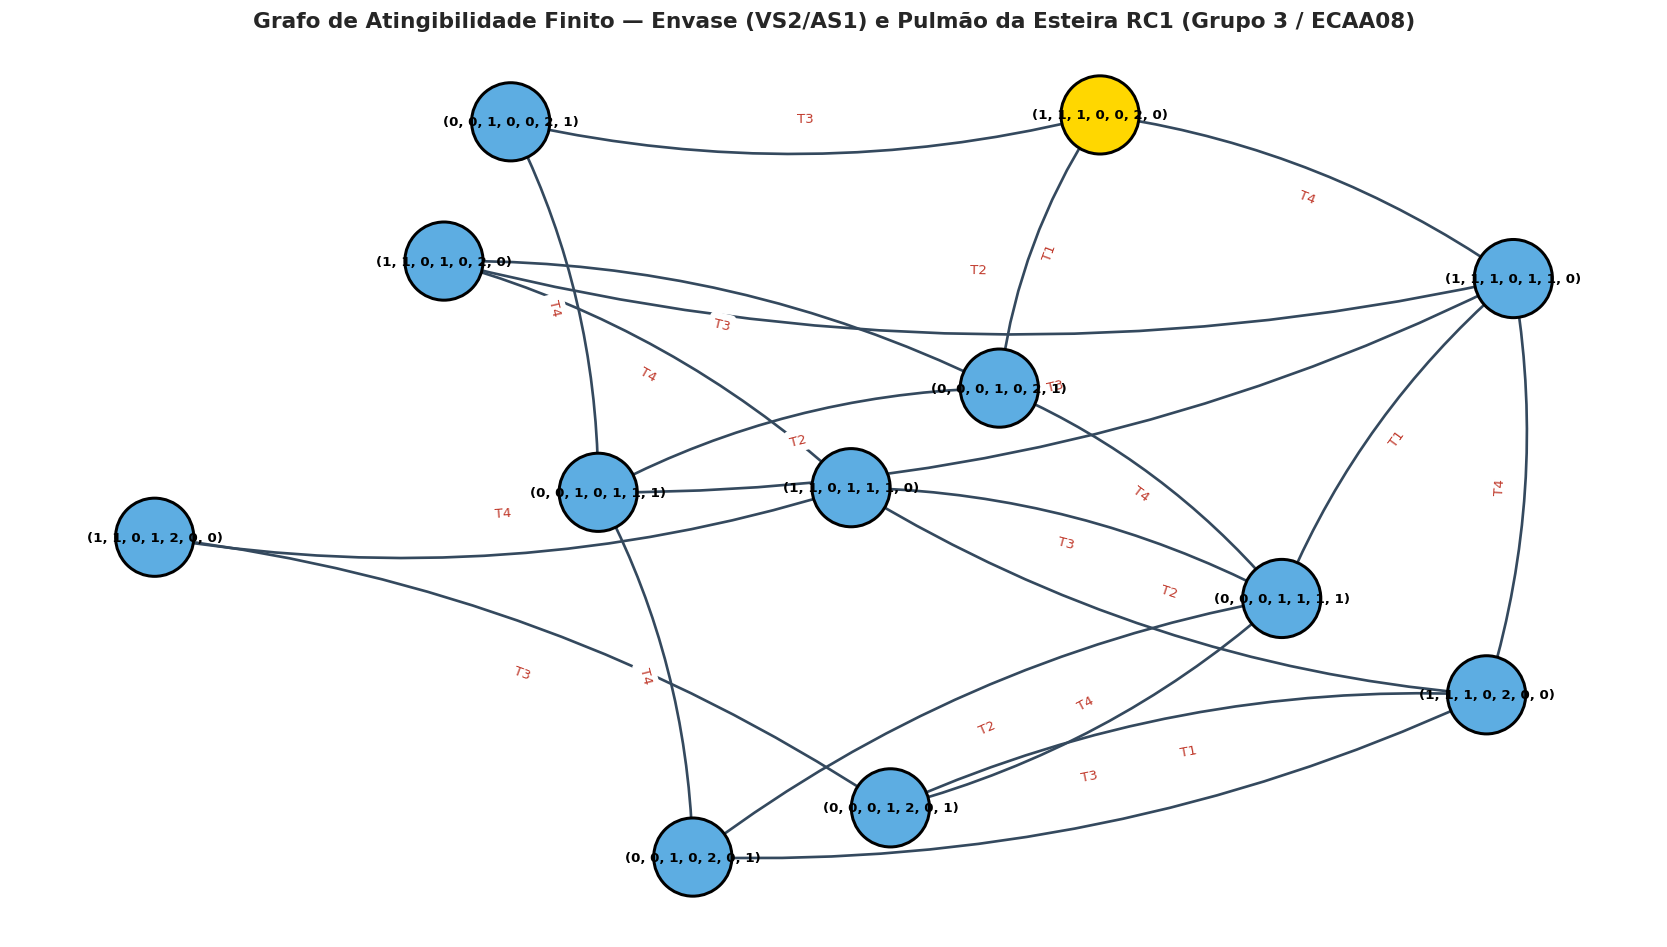

In [5]:
def plotar_grafo_atingibilidade(grafo, m0, titulo):
    fig, ax = plt.subplots(figsize=(14, 8))
    pos = nx.spring_layout(grafo, seed=42, k=1.4)

    cores = ["#FFD700" if n == m0 else "#5DADE2" for n in grafo.nodes]
    labels_nos = {n: d["label"] for n, d in grafo.nodes(data=True)}

    nx.draw_networkx_nodes(grafo, pos, node_color=cores, node_size=2200, edgecolors="black", linewidths=1.8, ax=ax)
    nx.draw_networkx_labels(grafo, pos, labels=labels_nos, font_size=8, font_weight="bold", ax=ax)

    nx.draw_networkx_edges(
        grafo, pos,
        edge_color="#34495E",
        width=1.6,
        arrows=True,
        arrowsize=18,
        connectionstyle="arc3,rad=0.12",
        ax=ax
    )

    edge_labels = {(u, v): d["transicao"].split("_")[0] for u, v, d in grafo.edges(data=True)}
    nx.draw_networkx_edge_labels(grafo, pos, edge_labels=edge_labels, font_size=8, font_color="#C0392B", ax=ax)

    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plotar_grafo_atingibilidade(
    grafo_B,
    M0_B,
    "Grafo de Atingibilidade Finito — Envase (VS2/AS1) e Pulmão da Esteira RC1 (Grupo 3 / ECAA08)"
)